# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [3]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [4]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,14.189159,7.205170,S-G1
1,1,osimertinib,B,tago-01560,1.031097,13.491245,P
2,2,osimertinib,A,tago-02253,14.651874,7.435656,S-G1
3,3,osimertinib,A,tago-01478,13.919818,-3.705924,S-syn
4,4,osimertinib,A,tago-02626,14.527276,6.953301,S-G1


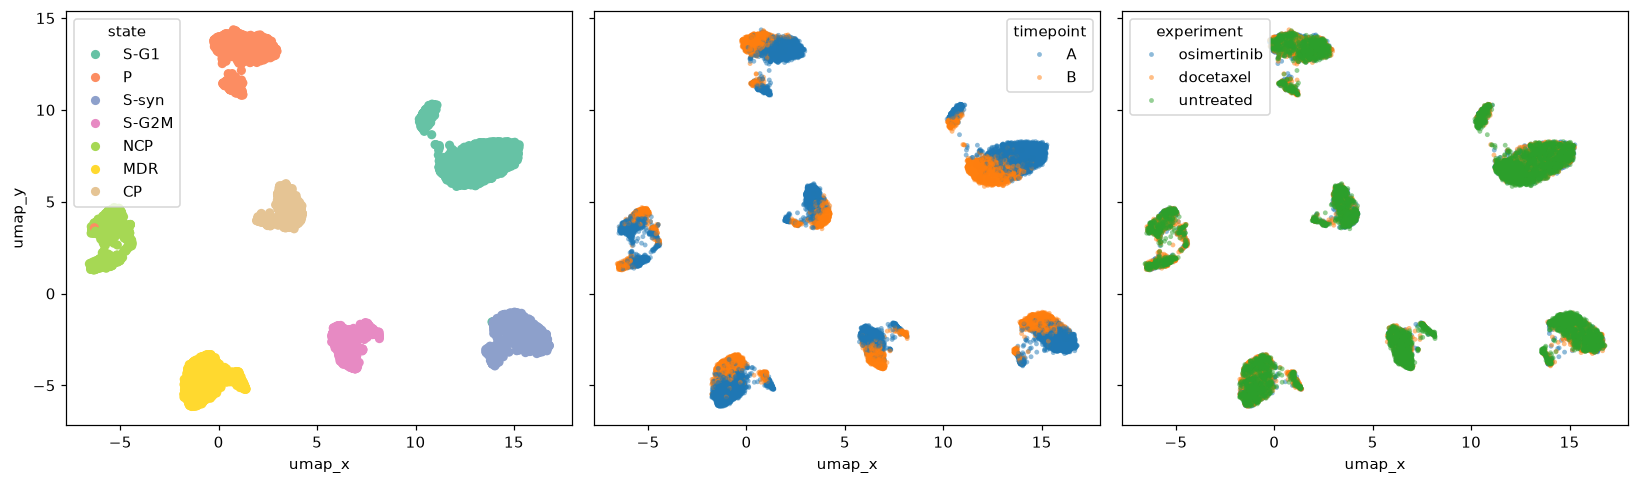

In [5]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 1. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [6]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [7]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [8]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [9]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [10]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [11]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

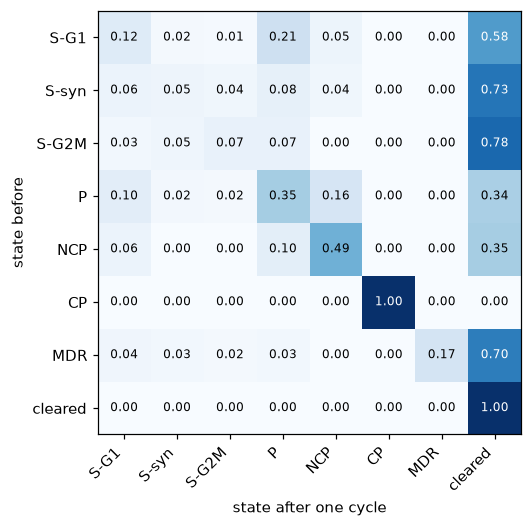

In [12]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

> In order to identify other thats that are also absorbing under osimertinib, we need to look for very high values in the matrix. We see that CP also have a value of 1.00, so cells that start in the CP state at time A always have a descent in that same CP state at time B. This means that the osimertinib treatment does not influence the states of cells that are starting in CP: none of the cells died and none switched to other states. This lack of affect indicates that osimertinib does not serve as a treatment for cells in the CP state. No other states have values close to 1 along the diagonal so this is hte only state that also approximately absorbs under osimertinib.

## 2. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [13]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [14]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [15]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

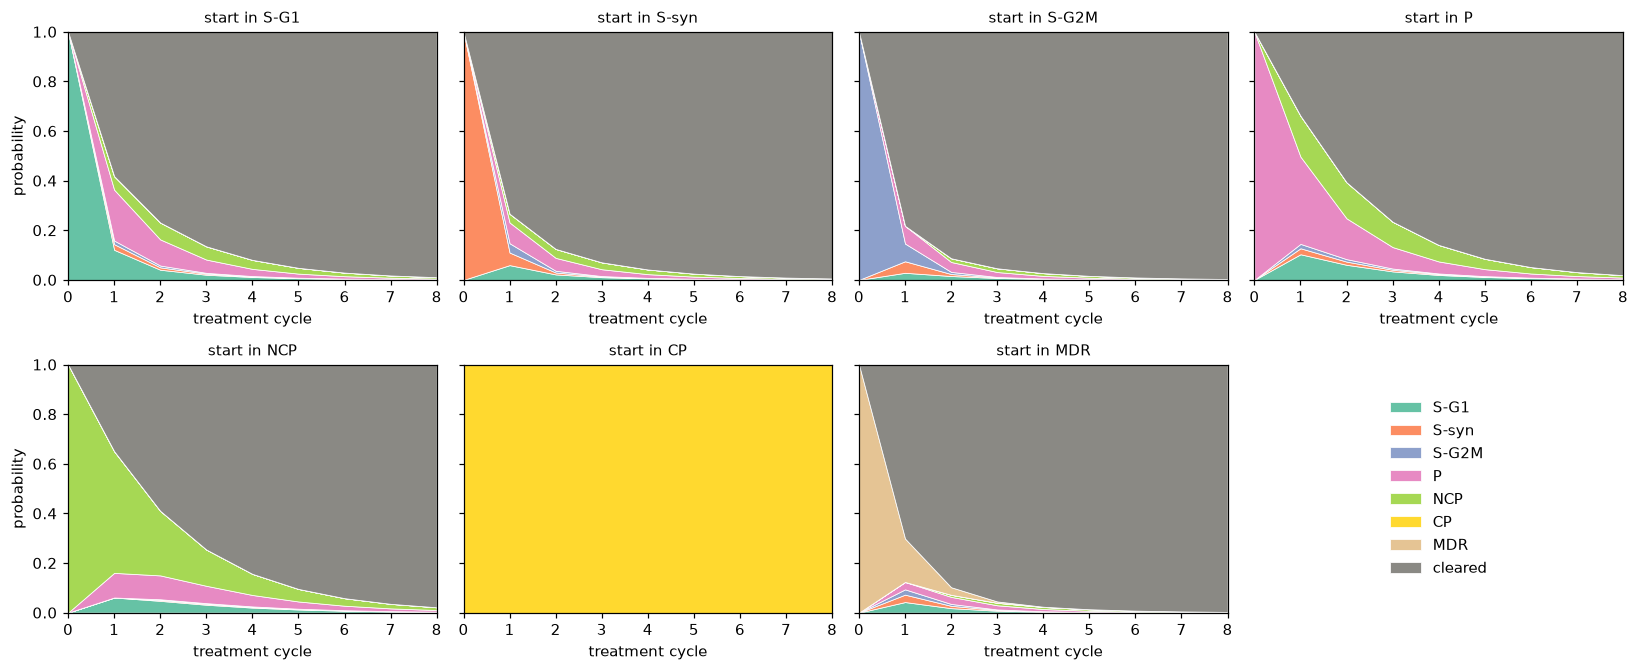

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [16]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>

In [17]:
# defining the number of cycles to simulate
num_cycles = 30
# updating the code from the cell above to run the simulations
alive = pd.DataFrame({s: 1 - evolve(basis(s, P_hat), P_hat, num_cycles)[:, -1] for s in STATES})
# displaying the amount of cells alive in each state for the given cycles
display(alive.loc[[0, 1, 3, 5, 10, 15, 20, 25, 30]].T.round(4))

# first cycle at which less than 1% of the starting probability is still alive
#print({s: (int((alive[s] < 0.01).idxmax()) if (alive[s] < 0.01).any() else None) for s in STATES})

,0,1,3,5,10,15,20,25,30
S-G1,1.0,0.4181,0.1352,0.0485,0.0040,0.0003,0.0000,0.0,0.0
S-syn,1.0,0.2665,0.0707,0.0252,0.0021,0.0002,0.0000,0.0,0.0
S-G2M,1.0,0.2179,0.0467,0.0163,0.0013,0.0001,0.0000,0.0,0.0
P,1.0,0.6615,0.2344,0.0851,0.0070,0.0006,0.0000,0.0,0.0
NCP,1.0,0.6506,0.2543,0.0955,0.0080,0.0007,0.0001,0.0,0.0
CP,1.0,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0,1.0
MDR,1.0,0.2985,0.0451,0.0136,0.0011,0.0001,0.0000,0.0,0.0


- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?

> After 20 cycles, pretty much all of the cells in every state but CP were gone (some still left in NCP). After 25 cycles, every cell is dead except for the cells in the CP state. All of the cells in CP stay alive, aligning with our previous findings and again confirming that osimertinib acts as a treatment for all tumor cells except for those in CP.

- Of the states that can be cleared, which tumor lasts the longest?

> All of the states can be cleared except for CP, and we see from the later cycles in the table that NCP survives the longest for the remaining states. Most of the states die out after 15 rounds of treatment but at 20 cycles, NCP is the only non-zero count excluding CP. The second longest lasting state is P, which is the state before NCP so the surviving cells in state P can transition to the NCP state, explaining some of the reason that this state persists the longest.

- Which starting state sticks around for the most cycles of drug?

> CP sticks around for the most cycles of the drug because osimertinib does not affect these cells in CP (no death or transition). So, no matter how many cycles are run, the cells in CP will stay in CP (unless they dies from other factors).

- Which starting state results in the highest proportion of alive cells after three cycles?

> After 3 cycles, the CP state has the highest proportion of alive cells (obviously as discussed above). The state with the second higher proportion of alive cells is NCP (0.2453), followed by P (0.2344). This trend is consistent from what we answer in the second bullet of this question.  States like S-syn, MDR, and S-G2M already have values below 0.1, meaning that after 3 cycles more than 90% of the cells in these states have died or transitioned. So, we can identify the states that persist the longest and shortest under the osimertinib drug, implying which states osimertinib is most effective against.

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

state
S-G1       0.247000
S-syn      0.148333
S-G2M      0.099444
P          0.152556
NCP        0.102444
CP         0.097222
MDR        0.153000
cleared    0.000000
Name: proportion, dtype: float64


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


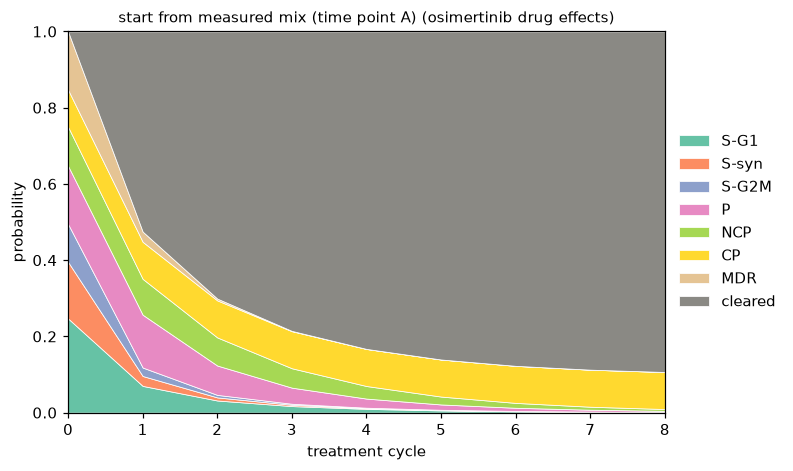

In [18]:
# Your code here

# set this equal to the starting vector from timepoint A

# first filtering to only the time point A like in cell 9
at_A = cells[cells.timepoint == "A"]

# updating cell 10 counts like, but now not setting the state because we want all of them
# this gets the proportion of cells at each state
pi_mix = (at_A["state"].value_counts(normalize=True)
            .reindex(OUTCOMES, fill_value=0))
print(pi_mix)

# evolve pi_mix and plot the results
# using the evolve function from before to evolve this like in cell 24
traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

# now plotting using plot_trajectory function from cell 25
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_trajectory(traj_mix, ax, "start from measured mix (time point A) (osimertinib drug effects)")
ax.set_ylabel("probability")
handles, labels = ax.get_legend_handles_labels() # no more indexing to the subplots
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False) # labels not outcomes now
plt.show()

<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

- Which state ends up dominating the remaining cluster? 

> From the plot, we can see that the cleared state dominates the remaining cluster (around 90% of the cells are in the clearned state). However, this is not a true state since it captures the dead cells, so for the surviving cells the CP state dominates (around 10% of the total cells are still in this state and about 100% of the surviving cells are in this state).


- Will these cells ever be cleared?

> From before, we know that osimertinib does not serve as a treatment that will cause the CP cells to die or transition. So, these remaining CP cells will never be cleared by osimertinib, indicting that we will need another drug to address these cells.


- How does the long-run endpoint relate to the transition matrix?

> The long-run endpoint can be explained by the transition matrix. The transition matrix has two states that are "absorbing", meaning that they have a 1 on the diagonal so all cells in that state stay in that state. These states are CP and cleared. So, the transition matrix tells us that cells in these two states will never go away, explaining the long-run behavior we see in the plot of these two states making up almost all of the states after 8 cycles. In general, the transition matrix shows how cells switch between states (or how they do not switch), and that can be applied to see where the cells will end up in the long run. This can evolve into the idea of an asymptote in which, given a starting proportion of cells in each state, we can predict the resulting proportion of cells in each state.

## 3. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [19]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
P_osi = P_hat.to_numpy()

# now applying everything to docetaxel
# updating cell 9
doc = cells[cells["experiment"] == "docetaxel"]
at_A_doc = doc[doc.timepoint == "A"][["lineage_tag", "state"]]
at_B_doc = doc[doc.timepoint == "B"][["lineage_tag", "state"]]

pairs_doc = pd.merge(at_A_doc, at_B_doc, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_doc["state_B"] = pairs_doc["state_B"].fillna("cleared")

# updating cell 10
counts_doc = (pd.crosstab(pairs_doc.state_A, pairs_doc.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_doc = counts_doc.div(counts_doc.sum(axis=1), axis=0)

# updating cell 11
assert np.allclose(P_doc.sum(axis=1), 1), "Every row should sum to 1."

# updating cell 15
P_doc.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_doc.columns})

# now applying everything to drug holiday/untreated
# updating cell 9
hol = cells[cells["experiment"] == "untreated"]
at_A_hol = hol[hol.timepoint == "A"][["lineage_tag", "state"]]
at_B_hol = hol[hol.timepoint == "B"][["lineage_tag", "state"]]

pairs_hol = pd.merge(at_A_hol, at_B_hol, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs_hol["state_B"] = pairs_hol["state_B"].fillna("cleared")

# updating cell 10
counts_hol = (pd.crosstab(pairs_hol.state_A, pairs_hol.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_holiday = counts_hol.div(counts_hol.sum(axis=1), axis=0)

# updating cell 11
assert np.allclose(P_holiday.sum(axis=1), 1), "Every row should sum to 1."

# updating cell 15
P_holiday.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_holiday.columns})

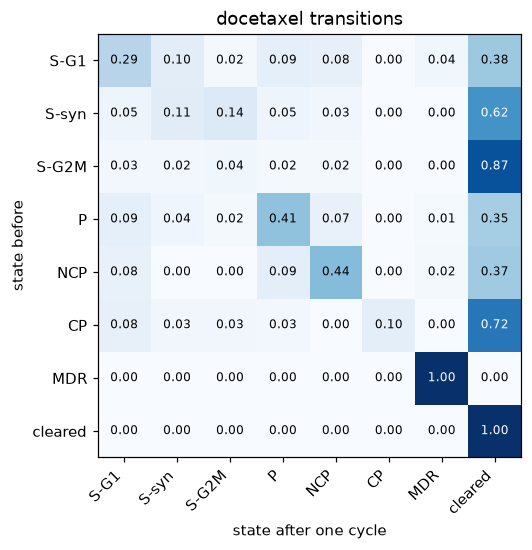

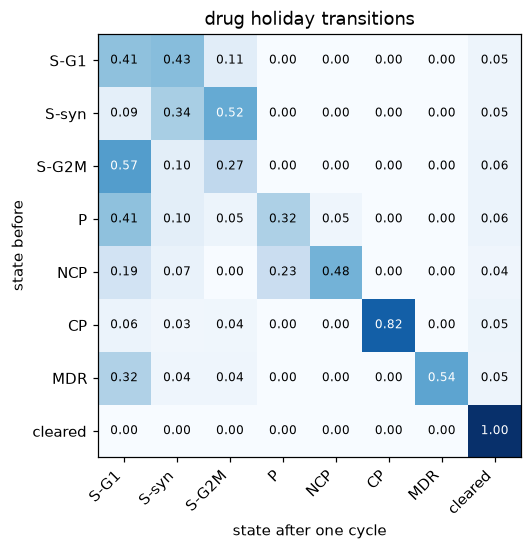

In [20]:
#Plot the transition matrices for docetaxel and the drug holiday.

# using the show_matrix function from cell 17 but adding title

# plotting transition matrix for docetaxel
show_matrix(P_doc, title="docetaxel transitions", ax=None)
# plotting transition matrix for drug holiday
show_matrix(P_holiday, title="drug holiday transitions", ax=None)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


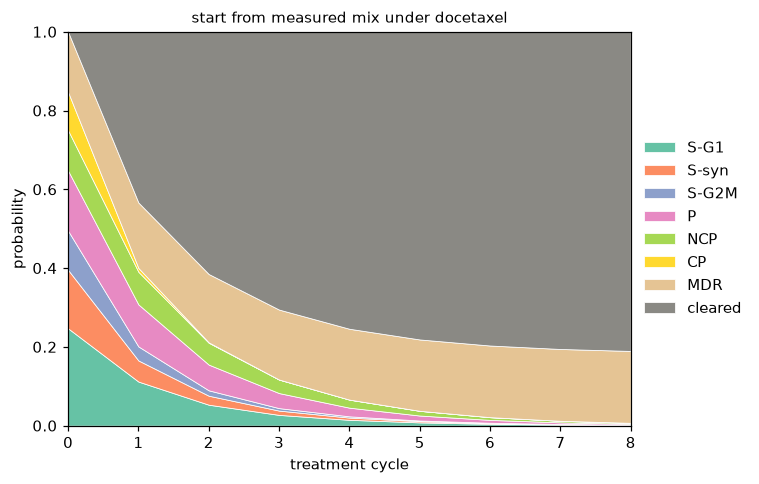

In [21]:
# Simulate the evolution of pi_mix under docetaxel 

# using evolve function from cell 21
# evolve from cell 20, table as in cell 23, plot_trajectory and legend from cell 25, pi_mix from cell 28
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

# using code from cell 26 to plot
fig, ax = plt.subplots(figsize=(7, 4.5)) # added with help of Claude because the ax parameter was not defined and causing a flot with 0 axis
plot_trajectory(traj_doc, ax, title="start from measured mix under docetaxel")
ax.set_ylabel("probability")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, labels, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.tight_layout()
plt.show()

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?

> In the transition matrix with docetaxel, there are two absorbing states indicated by the 1's found on the diagonal. These two states are MDR and cleared, so any cell that enters this state will not leave this state under docetaxel. We can also see that for most rows, the largest value lies in the cleared column, meaning that most of the cells from all states but MDR go to cleared under docetaxel. Putting this together, docetaxel serves as a treatment for all tumor cells except for those in MDR. Comparing this to the osimertinib transition matrix, we can see that both drugs have two absorbing states, one of which is always cleared. States P and NCP are also the two rows with the highest remaining values on the diagonal, indicating that both drugs struggle to clear one state of cells at all, and that NCP and P are both cleared the slowest by them.

> Shifting to the drug holiday transition matrix, things look different from the two drugs. There is only one absorbing state, and that is cleared. Cleared is always an absorbing state because once a cell is cleared it cannot possibly transition into another state. We see that the values that lie on the diagonal are larger, meaning more cell tend to stay in their current state during the drug holiday. The values in the last column for cleared are also much lower, indicating that many fewer tumor cells die when they are not treated by drugs. Comparing this to osimertinib, the drug holiday does not effectively kill tumor cells of any kind and has only the promised absorbing state of cleared.


2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

> After simulating the mixed tumor under 8 rounds of docetaxel like the notebook example, we can see the transition matrix take shape. All of the cell states fade to 0 over time, except for the two absorbing states. After the 8 rounds, pretty much only MDR cells and cleared cells exist. About 20% of the original cells are now in the MDR state, and 80% are in the cleared state. We know that these proportions will not be shifted by additional founds of docetaxel because these are the absorbing states where cell cannot transition otu of. So, docetaxel is not an effective drug for kill all of the cells in this mixed tumor.

## 4. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

In [41]:
P_osi_doc=P_doc.to_numpy() @ P_osi



In [47]:
P_doc_osi=P_osi @ P_doc.to_numpy()

In [49]:
pd.DataFrame(evolve(pi_mix, P_osi_doc, n_cycles=4), columns= OUTCOMES).round(4)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.2470,0.1483,0.0994,0.1526,0.1024,0.0972,0.1530,0.0000
1,0.0409,0.0144,0.0116,0.0807,0.0662,0.0097,0.0291,0.7474
2,0.0122,0.0034,0.0026,0.0269,0.0281,0.0010,0.0058,0.9200
3,0.0040,0.0010,0.0008,0.0091,0.0106,0.0001,0.0013,0.9732
4,0.0014,0.0003,0.0002,0.0031,0.0038,0.0000,0.0003,0.9908


In [50]:
pd.DataFrame(evolve(pi_mix, P_doc_osi, n_cycles=4), columns= OUTCOMES).round(4)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.2470,0.1483,0.0994,0.1526,0.1024,0.0972,0.1530,0.0000
1,0.0498,0.0195,0.0123,0.0763,0.0582,0.0097,0.0333,0.7409
2,0.0147,0.0050,0.0028,0.0256,0.0247,0.0010,0.0082,0.9180
3,0.0048,0.0015,0.0008,0.0086,0.0093,0.0001,0.0023,0.9725
4,0.0016,0.0005,0.0003,0.0030,0.0033,0.0000,0.0007,0.9906


In [45]:
pd.DataFrame(evolve(pi_mix, P_osi, n_cycles=8), columns= OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


In [46]:
pd.DataFrame(evolve(pi_mix, P_doc, n_cycles=8), columns= OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


In [51]:
pd.DataFrame(evolve(pi_mix, P_holiday, n_cycles=8), columns= OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.309,0.199,0.148,0.073,0.056,0.080,0.083,0.052
2,0.302,0.233,0.187,0.036,0.030,0.065,0.045,0.101
3,0.291,0.238,0.210,0.019,0.016,0.054,0.025,0.148
4,0.283,0.234,0.215,0.010,0.008,0.044,0.013,0.192
5,0.274,0.227,0.212,0.005,0.004,0.036,0.007,0.235
6,0.262,0.219,0.206,0.003,0.002,0.030,0.004,0.275
7,0.250,0.210,0.198,0.001,0.001,0.024,0.002,0.313
8,0.239,0.201,0.190,0.001,0.001,0.020,0.001,0.349


In [59]:
pd.DataFrame(evolve(basis("MDR", P_hat), P_holiday, n_cycles=8), columns= OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.000,0.000,0.000,0.0,0.0,0.0,1.000,0.000
1,0.319,0.044,0.044,0.0,0.0,0.0,0.542,0.051
2,0.334,0.181,0.093,0.0,0.0,0.0,0.294,0.099
3,0.301,0.228,0.167,0.0,0.0,0.0,0.159,0.145
4,0.291,0.231,0.202,0.0,0.0,0.0,0.086,0.189
5,0.284,0.229,0.209,0.0,0.0,0.0,0.047,0.231
6,0.273,0.224,0.207,0.0,0.0,0.0,0.025,0.271
7,0.259,0.216,0.202,0.0,0.0,0.0,0.014,0.310
8,0.246,0.206,0.194,0.0,0.0,0.0,0.007,0.346


>It does matter if the first treatment is osimertinib or docetaxel since matrix multiplication is not commutative. However, in practice, we can see that starting with one or the other only makes a very small change in the end result. Starting with osimertinib and alternating leads to a cleared rate of 99.08% whereas starting with docetaxel and alternating for 8 rounds leads to a cleared rate of 99.06% so while mathematically they are different, the differences between them are so small that it doesn't really matter.
>
> For this data, there is no need for a drug holiday however, if alternating the drugs tended to approach a steady state with a large proportion of drug resistant cells, then we would want to take a break to let them evolve into less resistant cell types. Since for us, the steady state is all cleared cells, we don't have to worry here.



Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.


In [99]:
outcomes_alternate=[]
outcomes_osi=[]
outcomes_doc=[]
outcomes_holiday=[]
for outcome in OUTCOMES:
    #print(f'If entire tumor is {outcome} treating with alternating treatment will clear {pd.DataFrame(evolve(basis(outcome, P_hat), P_doc_osi, n_cycles=4), columns= OUTCOMES).round(3).iloc[-1]['cleared']}')
    outcomes_alternate.append(pd.DataFrame(evolve(basis(outcome, P_hat), P_doc_osi, n_cycles=4), columns= OUTCOMES).round(3).iloc[-1]['cleared'])
    outcomes_doc.append(pd.DataFrame(evolve(basis(outcome, P_hat), P_doc, n_cycles=8), columns= OUTCOMES).round(3).iloc[-1]['cleared'])
    outcomes_osi.append(pd.DataFrame(evolve(basis(outcome, P_hat), P_osi, n_cycles=8), columns= OUTCOMES).round(3).iloc[-1]['cleared'])
    outcomes_holiday.append(pd.DataFrame(evolve(basis(outcome, P_hat), P_holiday, n_cycles=8), columns= OUTCOMES).round(3).iloc[-1]['cleared'])

combo_treatment=pd.DataFrame([outcomes_alternate, outcomes_osi, outcomes_doc, outcomes_holiday], columns=OUTCOMES).T
combo_treatment.rename(columns={0:"Alternating treatment", 1: "Osi only", 2:"Doc only", 3:"Holiday"})


,Alternating treatment,Osi only,Doc only,Holiday
S-G1,0.990,0.989,0.927,0.348
S-syn,0.995,0.994,0.988,0.349
S-G2M,0.997,0.996,0.994,0.355
P,0.983,0.981,0.945,0.357
NCP,0.981,0.978,0.932,0.337
CP,0.994,0.000,0.990,0.350
MDR,0.995,0.997,0.000,0.346
cleared,1.000,1.000,1.000,1.000


> Regardless of the starting make up of a tumor (given that a cell is only 1 type), alternating treatment for 8 rounds leads to a cleared rate of above 98% for every type.
>
> Treating with Osi only clears 97% of cells unless the cell starts in CP mode since CP is resistant to Osi.
>
> Similarly, Doc clears 93% of all cells unless the cell starts in MDR mode since MDE is resistant to Doc.
>
> Finally, for any particular cell type start, with no treatment, after 8 rounds of treatment we expect about 35% of cells to be cleared.
>
> If we assume that a cell of different types will be some linear combination and average of the single type cells, then alternating treatment will be the best option since it clears almost all cells of every type. So every possible starting make up of the cell will still be effectively cleared with alternating treatment. 
> 
> As for the length of the test, this is a personal choice. Just like how hand sanitizer clears 99.99% of bacteria, the as $\lim_{\text{cycles}\to \infty} p(\text{cleared}=1)$. The only option is how sure you want to be. If clearing out 98% of the tumor is enough to remove the rest via surgery, then 8 rounds will be plenty. If the tumor only needs to be 50% cleared to do surgery, then only 2 cycles (one of each medicine) are required. If 99.99% needs to be cleared no matter what, then a total of 18 cycles are needed. Since each treatment cycle is damaging to the patient, hopefully you can opt for a lower percentage of cleared and then do surgery.

## 5 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [23]:
rng = np.random.default_rng(100)

In [24]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [25]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

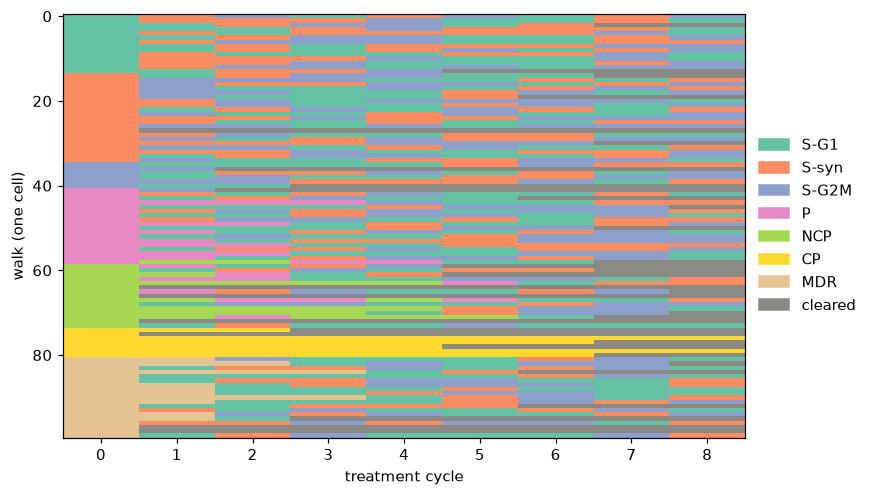

In [26]:
N_WALKS = 100
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [27]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

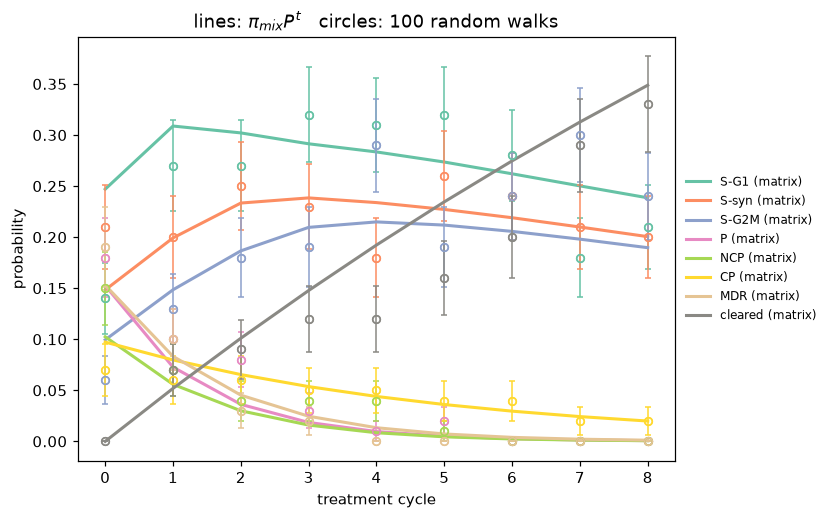

In [28]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

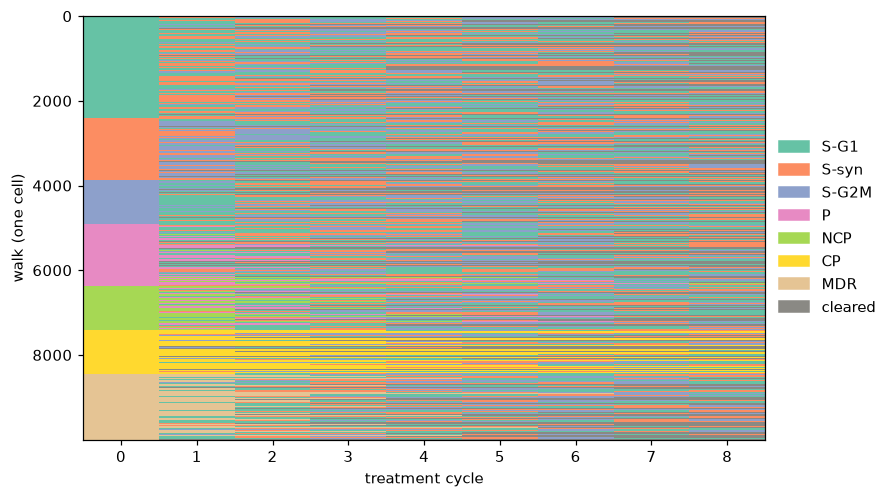

In [32]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

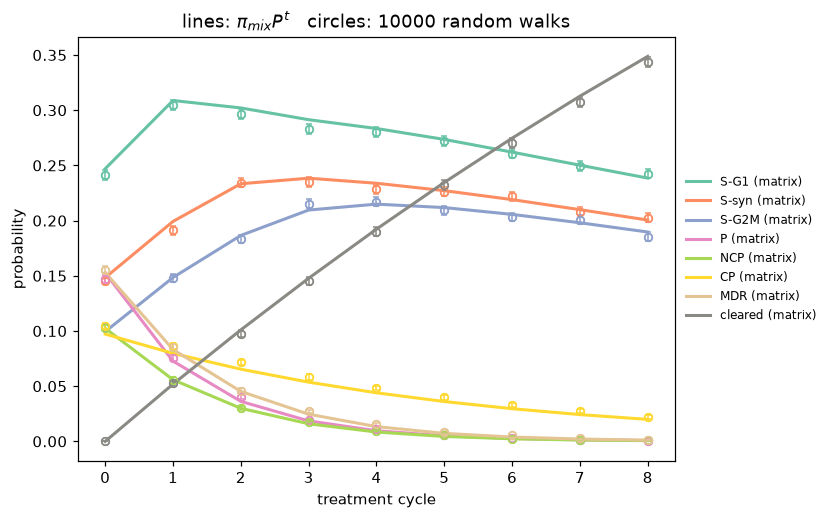

In [33]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

## 6. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [29]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

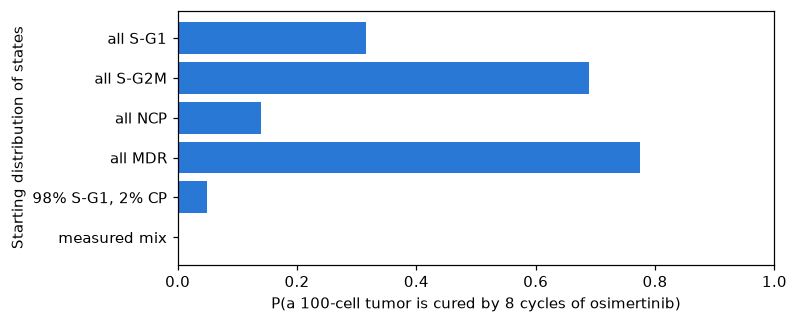

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.315,1.105,0.000
all S-G2M,0.690,0.365,0.000
all NCP,0.140,2.095,0.000
all MDR,0.775,0.245,0.000
"98% S-G1, 2% CP",0.050,3.220,0.644
measured mix,0.000,10.780,0.910


In [30]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_osi, 8      # this simulation: 8 cycles of osimertinib
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

## 7. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [31]:
# write a function that runs 1000 random walks and saves them
# you will use this function 100 times to generate a simulated set of tumors

# go through each random walk and if a persister stays for 3+ consecutive cycles, add to tally
# count up cells that stayed in persister state consecutively out of total cells

# repeat for all tumors

# report mean +/- SEM for osimertinib

# compare to 10% threshold using 95% CI or a hypothesis test



<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>